# Stage 5 (part 2) — TFT, deep classification, apples-to-apples comparison

| Part | Prompt | Code |
|---|---|---|
| 1 | 5.4 Temporal Fusion Transformer (quantiles, explainability) | `deep_ts.run("tft", …)`, darts `TFTExplainer` |
| 2 | 5.5 rain/no-rain from deep models (options 1–3) | `src/deep_cls.py` |
| 3 | 5.6 baselines + 10 classical + 3 deep on the same split | `experiment.run_cv(split="dl")`, `src/compare.py` |

**Approved decisions for this part (DECISIONS 5.7–5.9):** the primary lookback is fixed **in advance at L = 14** for all three deep
models (Stage 1 PACF; flat lookback curves in part 1) — no post-hoc lookback selection. TFT: 5 seeds at L = 14, 1 seed each at L = 30 and
L = 60 for the sensitivity curve (a TFT run takes ≈ 5.5 min on 4 CPU cores). The classical models are refitted on **exactly the same split**:
training targets 1981–2014, inner slice 2012–2014 for early stopping / smearing / thresholds, validation targets 2015–2019.

**Correction to part 1 (rule 12):** part 1 documented TiDE's `temporal_decoder_hidden` as 16, but a comment inserted by a text edit hid
that argument, so every TiDE run used darts' default **32**. All part-1 TiDE results are internally consistent; the code now sets 32
explicitly and the documentation is corrected.

**The test years are never loaded.**

### Step 1 — Setup

**WHAT:** imports, versions, the validation references for regression and classification.

**Look for:** darts 0.48.0; validation index of 1,826 days.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, darts
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import deep_ts as D, deep_cls as DC, experiment as E, models as Mo, reg_variants as RV, compare as C, metrics as M, splits as S

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
torch.set_num_threads(4)
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_colwidth", 45, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
REFS_REG, REFS_CLS = D.dl_references(), DC.cls_references()
SEEDS, L = [0, 1, 2, 3, 4], 14
print("darts", darts.__version__, "| validation days:", len(REFS_REG[0]), "| quantiles:", D.QUANTILES)

darts 0.48.0 | validation days: 1826 | quantiles: [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]


**Interpretation:** same software stack as part 1 (darts 0.48.0, CPU only). The validation period has 1,826 target days (2015-01-01 to
2019-12-31) and the TFT predicts seven quantiles.

**Decision:** continue with this stack. Every model in this notebook is scored on these 1,826 days.

**Paper note:** *All models were evaluated on the same 1,826 validation days (target dates 2015–2019).*

### Step 2 — TSMixer and TiDE at the fixed lookback L = 14 (5 seeds), now also saving slice forecasts

**WHAT:** re-run TSMixer and TiDE (mm and log targets) at L = 14 with seeds 0–4. The code is unchanged for regression, but each run now also
stores the inner model's forecasts for the 2012–2014 slice, which the classification options (5.5) need for thresholds and calibration.

**WHY:** with L fixed in advance, every deep model is evaluated at the same, pre-registered lookback.

**Look for:** the same scores as in part 1 for configurations that were already run with these seeds (training is deterministic given the seed).

In [2]:
def run_and_score(kind, transform, L, seed, keep=False):
    r = D.run(kind, transform, L, seed, return_model=keep)
    out, info = r[0], r[1]
    if transform != "bin":
        s = D.score_and_store(out, info, kind, transform, L, seed, REFS_REG)
        head = s[s.metric == "MAE"].set_index("target")["value"].round(3).to_dict()
    else:
        head = {"mean p": round(out["p"].mean(), 3)}
    print(f"{kind:7s} {transform:3s} L={L} seed {seed}: {head} | best epoch {info['best_epoch']} | {info['fit_seconds']:.0f}s", flush=True)
    return r

t0 = time.time()
for kind in ("tsmixer", "tide"):
    for transform in ("mm", "log"):
        for seed in SEEDS:
            run_and_score(kind, transform, L, seed)
print(f"total {time.time() - t0:.0f}s")

tsmixer mm  L=14 seed 0: {'mm': 9.168} | best epoch 15 | 30s


tsmixer mm  L=14 seed 1: {'mm': 8.831} | best epoch 30 | 50s


tsmixer mm  L=14 seed 2: {'mm': 9.235} | best epoch 20 | 37s


tsmixer mm  L=14 seed 3: {'mm': 9.426} | best epoch 22 | 42s


tsmixer mm  L=14 seed 4: {'mm': 9.522} | best epoch 23 | 42s


...

tide    log L=14 seed 1: {'log_smear': 9.463, 'log_naive': 9.186} | best epoch 56 | 113s


tide    log L=14 seed 2: {'log_smear': 9.372, 'log_naive': 9.223} | best epoch 54 | 115s


tide    log L=14 seed 3: {'log_smear': 9.453, 'log_naive': 9.172} | best epoch 38 | 55s


tide    log L=14 seed 4: {'log_smear': 9.399, 'log_naive': 9.24} | best epoch 43 | 74s


total 1051s


**Interpretation:** at L = 14 the TSMixer and TiDE MAEs (TSMixer mm 8.83–9.52, log + smearing 9.01–9.32; TiDE mm 9.83–10.06,
log + smearing 9.37–9.48) are in the same range as in part 1, so the reruns reproduce the earlier behaviour.
- **Seed spread is wide for TSMixer.** One TSMixer mm seed (8.83) beats seasonal + persistence (9.02) and another (9.52) does not, so a single seed could have supported either conclusion. This is why rule 8 requires 5 seeds.
- **The best back-transform depends on the model.** For TiDE the naive expm1 forecast beats smearing on MAE (9.17–9.24 vs 9.37–9.48). Smearing targets the *mean* and raises every forecast, while MAE rewards the *median*. For TSMixer the opposite holds (smearing 9.01–9.32, naive 9.88–10.29): its naive forecasts are so low that the upward correction helps.

**Decision:** keep both TSMixer and TiDE at L = 14 with 5 seeds. The slice forecasts saved here are reused for the option-1 calibration in Part 2.

**Paper note:** *Across five seeds, the validation MAE of TSMixer varied by up to 0.7 mm, comparable to the differences between model families, which underlines the need to report seed-averaged results.*

# Part 1 — Prompt 5.4: Temporal Fusion Transformer

### Step 3 — What TFT does

TFT (Lim et al., 2021, *Temporal Fusion Transformers for interpretable multi-horizon time series forecasting*) combines:
1. **variable-selection networks (VSN):** for every time step, a small gated network produces a *softmax weight per input variable* and
   forms a weighted combination — separately for the encoder (past window: rain history, past weather, calendar) and the decoder (forecast day:
   calendar). These weights are what darts reports as encoder/decoder importances;
2. **gated residual networks (GRN):** gates (GLU) let the network switch off parts it does not need — a built-in regulariser;
3. **LSTM encoder–decoder:** local sequential processing of the window;
4. **interpretable multi-head attention:** the forecast day attends over the 14 past days (and itself); attention weights show which days
   the model "looks at";
5. **quantile outputs:** trained with the pinball (quantile) loss for τ ∈ {0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95} → a forecast distribution.

**Our configuration:** hidden size 16, 1 LSTM layer, 2 attention heads, hidden continuous size 8, dropout 0.1, same optimiser / early stopping /
refit protocol; target in mm (scaled). Quantiles are *equivariant* under monotone transforms, so a log target is not needed to get correct
medians — we use mm directly. Point forecasts: the **median** (q0.5) and the **mean of the quantile function** (average of the quantile knots,
tails truncated beyond 5 % / 95 %).

**Look for:** run time; best epochs.

In [3]:
t0 = time.time()
tft_model = tft_data = None
for seed in SEEDS:
    r = run_and_score("tft", "mm", L, seed, keep=(seed == 0))
    if seed == 0:
        tft_model, tft_data = r[2], r[3]
for L_ in (30, 60):
    run_and_score("tft", "mm", L_, 0)
print(f"total {time.time() - t0:.0f}s")

tft     mm  L=14 seed 0: {'q50': 9.627, 'qmean': 9.115} | best epoch 29 | 307s


tft     mm  L=14 seed 1: {'q50': 9.912, 'qmean': 9.298} | best epoch 22 | 270s


tft     mm  L=14 seed 2: {'q50': 9.41, 'qmean': 9.185} | best epoch 27 | 305s


tft     mm  L=14 seed 3: {'q50': 9.365, 'qmean': 9.1} | best epoch 25 | 269s


tft     mm  L=14 seed 4: {'q50': 9.91, 'qmean': 9.226} | best epoch 27 | 314s


tft     mm  L=30 seed 0: {'q50': 9.916, 'qmean': 9.282} | best epoch 36 | 533s


tft     mm  L=60 seed 0: {'q50': 9.697, 'qmean': 9.186} | best epoch 33 | 695s


total 2693s


**Interpretation:** each TFT seed stopped at epoch 22–29 (out of a 60-epoch maximum) and took 270–314 s, about 6× TSMixer and about
60× CatBoost. q50 MAE ranged from 9.37 to 9.91 and qmean MAE from 9.10 to 9.30. The single L = 30 and L = 60 runs took 533 s and 695 s.
The full TFT block took 45 minutes.

**Decision:** early stopping worked: no seed hit the epoch cap, so the TFT is not under-trained. We keep L = 14 as decided in advance.

**Paper note:** *The TFT converged after 22–29 epochs under early stopping on the 2012–2014 slice, at roughly 300 s of CPU time per fit.*

### Step 4 — TFT regression, pinball loss and interval coverage

**WHAT:** mean ± std over seeds of MAE, RMSE, bias, MSESS (vs climatology and vs seasonal + persistence), wet-day MAE, heavy-rain recall,
**pinball loss** (mean over the 7 quantile levels, mm) and **coverage** of the 80 % (q0.1–q0.9) and 90 % (q0.05–q0.95) intervals — for the
median and the quantile-mean point forecasts, next to TSMixer and TiDE (L = 14) and the references.

**WHY:** a probabilistic model must be judged on its distribution (pinball, coverage), not only on a point forecast.

**Look for:** coverage close to the nominal 80 % / 90 %; median vs mean point forecast (MAE vs bias); the last table is the lookback
sensitivity curve (count = number of seeds).

In [4]:
KEY = ["MAE", "RMSE", "bias", "MSESS", "MSESS_vs_seas_pers", "MAE_wet", "recall_ge20", "recall_ge50", "pinball", "coverage80",
       "coverage90", "best_epoch", "fit_seconds"]
r = pd.read_csv(D.RESULTS)
r = r[r.lookback == L]
g = r[r.metric.isin(KEY)].groupby(["model", "target", "metric"])["value"]
deep_reg = (g.mean().map("{:.3f}".format) + " ± " + g.std().fillna(0).map("{:.3f}".format)).unstack("metric").reindex(columns=KEY)
deep_reg["n_seeds"] = r.groupby(["model", "target"])["seed"].nunique()
deep_reg.to_csv(TAB / "05_deep_regression_L14.csv")
display(deep_reg)
va, y, refs = REFS_REG
display(pd.DataFrame({k: E.score("reg", y, refs[k], np.nan, refs, va) for k in ("seasonal+persistence", "persistence", "climatology")}).T[KEY[:8]].round(3))
ra = pd.read_csv(D.RESULTS)
lb = ra[ra.metric.isin(["MAE", "MSESS", "pinball"]) & ra.target.isin(["mm", "log_smear", "qmean"])]
lb = lb.groupby(["model", "target", "lookback", "metric"])["value"].agg(["mean", "count"]).unstack("metric")
lb.round(3).to_csv(TAB / "05_lookback_sensitivity.csv")
lb.round(3)   # lookback sensitivity: TSMixer/TiDE L30/L60 from part 1 (3 seeds), TFT L30/L60 1 seed

metric                        MAE            RMSE            bias          MSESS MSESS_vs_seas_pers         MAE_wet    recall_ge20    recall_ge50        pinball     coverage80     coverage90       best_epoch       fit_seconds  \
model   target                                                                                                                                                                                                                      
tft     q50         9.645 ± 0.263  20.971 ± 0.488  -7.702 ± 0.738  0.176 ± 0.038     -0.255 ± 0.058  16.297 ± 0.533  0.346 ± 0.093  0.000 ± 0.000  2.963 ± 0.074  0.821 ± 0.009  0.892 ± 0.007   26.000 ± 2.646  292.694 ± 21.661   
        qmean       9.185 ± 0.082  19.599 ± 0.327  -5.104 ± 0.771  0.280 ± 0.024     -0.096 ± 0.037  14.979 ± 0.239  0.473 ± 0.068  0.000 ± 0.000  2.963 ± 0.074  0.821 ± 0.009  0.892 ± 0.007   26.000 ± 2.646  292.694 ± 21.661   
tide    log_naive   9.199 ± 0.031  19.556 ± 0.089  -5.766 ± 0.133  0.283 ± 0.006     -0.091 ± 0.010  15.322 ± 0.054  0.447 ± 0.016  0.082 ± 0.006            NaN            NaN            NaN  43.000 ± 13.000   80.442 ± 32.847   
        log_smear   9.434 ± 0.047  17.922 ± 0.014  -0.738 ± 0.195  0.398 ± 0.001      0.084 ± 0.001  14.993 ± 0.081  0.724 ± 0.006  0.233 ± 0.008            NaN            NaN            NaN  43.000 ± 13.000   80.442 ± 32.847   
        mm          9.912 ± 0.090  18.338 ± 0.107  -1.729 ± 0.096  0.370 ± 0.007      0.041 ± 0.011  14.895 ± 0.101  0.611 ± 0.004  0.205 ± 0.017            NaN            NaN            NaN  19.800 ± 10.616   38.175 ± 19.556   
tsmixer log_naive  10.072 ± 0.181  21.477 ± 0.345  -8.638 ± 0.392  0.136 ± 0.028     -0.316 ± 0.042  17.026 ± 0.364  0.163 ± 0.029  0.000 ± 0.000            NaN            NaN            NaN   30.200 ± 6.979    50.895 ± 9.089   
        log_smear   9.195 ± 0.136  19.347 ± 0.353  -5.962 ± 0.615  0.299 ± 0.025     -0.068 ± 0.039  15.015 ± 0.326  0.370 ± 0.040  0.068 ± 0.029            NaN            NaN            NaN   30.200 ± 6.979    50.895 ± 9.089   
        mm          9.236 ± 0.268  19.227 ± 0.383  -5.030 ± 0.470  0.307 ± 0.027     -0.055 ± 0.042  14.779 ± 0.277  0.444 ± 0.037  0.000 ± 0.000            NaN            NaN            NaN   22.000 ± 5.431    40.139 ± 7.247   

metric             n_seeds  
model   target              
tft     q50              5  
        qmean            5  
tide    log_naive        5  
        log_smear        5  
        mm               5  
tsmixer log_naive        5  
        log_smear        5  
        mm               5

,MAE,RMSE,bias,MSESS,MSESS_vs_seas_pers,MAE_wet,recall_ge20,recall_ge50
seasonal+persistence,9.019,18.725,-4.595,0.343,0.000,14.585,0.459,0.152
persistence,9.663,19.967,0.000,0.253,-0.137,15.951,0.675,0.492
climatology,10.974,23.102,-7.766,0.000,-0.522,17.955,0.000,0.000


mean                count              
metric                        MAE  MSESS pinball   MAE MSESS pinball
model   target    lookback                                          
tft     qmean     14        9.185  0.280   2.963   5.0   5.0     5.0
                  30        9.282  0.264   3.007   1.0   1.0     1.0
                  60        9.186  0.287   2.926   1.0   1.0     1.0
tide    log_smear 14        9.434  0.398     NaN   5.0   5.0     NaN
                  30        9.473  0.396     NaN   3.0   3.0     NaN
                  60        9.584  0.393     NaN   3.0   3.0     NaN
        mm        14        9.912  0.370     NaN   5.0   5.0     NaN
                  30        9.787  0.385     NaN   5.0   5.0     NaN
                  60        9.863  0.379     NaN   3.0   3.0     NaN
tsmixer log_smear 14        9.195  0.299     NaN   5.0   5.0     NaN
                  30        9.230  0.302     NaN   3.0   3.0     NaN
                  60        9.301  0.291     NaN   3.0   3.0     NaN
        mm        14        9.236  0.307     NaN   5.0   5.0     NaN
                  30        9.431  0.284     NaN   3.0   3.0     NaN
                  60        9.492  0.286     NaN   3.0   3.0     NaN

**Interpretation:**
- **The median is a poor point forecast for rainfall.** q50 has MAE 9.65 ± 0.26 and bias −7.7 mm/day, and it never reaches 50 mm (recall≥50 = 0). The distribution is right-skewed with a point mass at zero, so the median lies far below the mean and systematically under-predicts.
- **The quantile mean (qmean) is better on every point metric:** MAE 9.19 ± 0.08, bias −5.1, MSESS 0.28. It is still worse than seasonal + persistence (MAE 9.02, MSESS 0.34).
- **The *distribution* is the TFT's strength.** Pinball loss is 2.96, the 80 % interval (q0.1–q0.9) covers 82.1 ± 0.9 % of days, and the 90 % interval covers 89.2 %. Both are within about 2 points of nominal.
- **Lookback barely matters** (qmean MAE 9.19 / 9.28 / 9.19 at L = 14 / 30 / 60, single seeds for 30 and 60). This matches TSMixer (9.24 / 9.43 / 9.49) and TiDE (9.43 / 9.47 / 9.58): two weeks of history contain almost all the usable signal.

**Decision:** report the TFT as a *probabilistic* model (quantiles, coverage). For point comparisons use qmean, not q50. L = 14 is confirmed as adequate.

**Paper note:** *The TFT's central 80 % prediction interval covered 82.1 % of validation days, but its median forecast was biased low by 7.7 mm day⁻¹ because the conditional median of a zero-inflated variable is close to zero.*

### Step 5 — Are TFT's quantiles calibrated? Reliability of quantiles and a fan chart

**WHAT:** (left) for every quantile level τ, the observed fraction of days with rain ≤ q_τ (should equal τ), per seed; (right) the predicted
median and 80 % / 90 % intervals against observed rain for the 2018 monsoon (seed 0).

**WHY:** coverage summarises two quantiles; the reliability curve checks all seven, and the fan chart shows *where* the intervals fail.

**Look for:** points on the diagonal; intervals that widen in the monsoon.

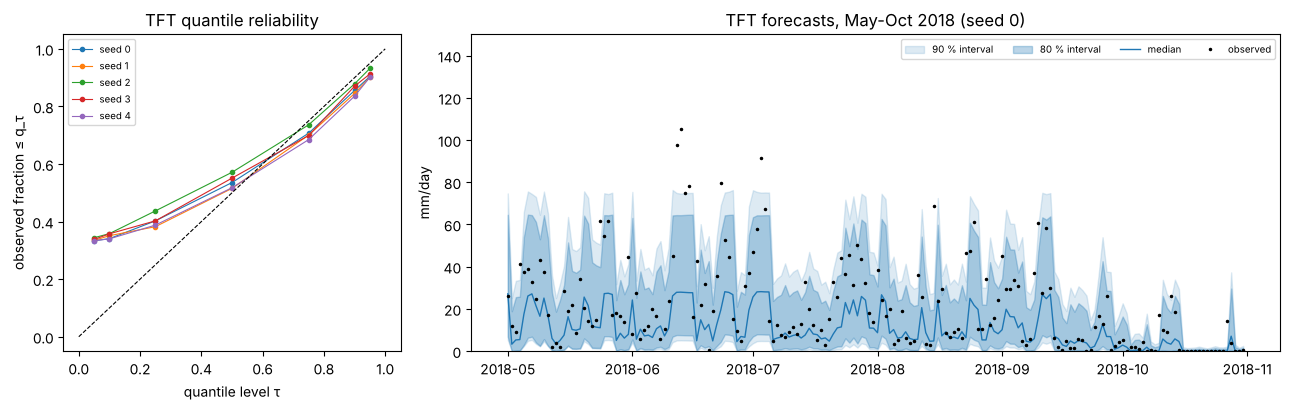

In [5]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 2.4]})
for seed in SEEDS:
    o = pd.read_parquet(D.DEEP_DIR / f"tft_mm_L14__seed{seed}.parquet")
    a0.plot(D.QUANTILES, [(o["y_true"] <= o[f"q{t}"]).mean() for t in D.QUANTILES], "o-", ms=3, lw=0.8, label=f"seed {seed}")
a0.plot([0, 1], [0, 1], "k--", lw=0.8); a0.set(xlabel="quantile level τ", ylabel="observed fraction ≤ q_τ", title="TFT quantile reliability")
a0.legend(fontsize=7)
o = pd.read_parquet(D.DEEP_DIR / "tft_mm_L14__seed0.parquet").loc["2018-04-30":"2018-10-30"]
t = S.target_dates(o.index)
a1.fill_between(t, o["q0.05"], o["q0.95"], color="tab:blue", alpha=0.15, label="90 % interval")
a1.fill_between(t, o["q0.1"], o["q0.9"], color="tab:blue", alpha=0.3, label="80 % interval")
a1.plot(t, o["q0.5"], color="tab:blue", lw=1, label="median"); a1.plot(t, o["y_true"], "k.", ms=3, label="observed")
a1.set(ylabel="mm/day", title="TFT forecasts, May-Oct 2018 (seed 0)", ylim=(0, 150)); a1.legend(fontsize=7, ncol=4)
fig.tight_layout(); save(fig, "05_tft_quantiles.png"); plt.show()

**Interpretation:** the left panel shows the observed fraction of days with rain ≤ the predicted quantile, for each seed.
- **Middle and upper quantiles (τ = 0.5–0.95) are close to the diagonal.** All five seeds agree.
- **The upper tail is slightly too low.** About 9 % of days exceed q0.95 (nominal 5 %), and about 14 % exceed q0.9 (nominal 10 %).
- **The lower quantiles (τ ≤ 0.25) lie well above the diagonal** (≈ 0.34 at τ = 0.05). This is not a model failure. About a third of days have exactly 0 mm, and on those days the low quantiles are also 0, so "y ≤ q" is true by a tie. For a variable with a point mass at zero, lower-quantile reliability is not meaningful.
- **Fan chart (right):** the intervals widen in the monsoon and collapse to near zero in the dry season (late October), as they should. The median rarely exceeds about 30 mm, while observed peaks reach about 105 mm. Several extreme days fall above the 90 % band, consistent with the slightly low upper tail.

**Decision:** the quantiles are reliable enough in the wet range to derive a rain probability (option 2, Part 2). We do not post-calibrate them for regression, and we report the low upper tail as a limitation.

**Paper note:** *The TFT's central and upper quantiles were close to nominal reliability, although the 95th percentile was exceeded on about 9 % of days, indicating that extreme rainfall was somewhat under-represented in the predicted distribution.*

### Step 6 — Variable-selection importances and attention

**WHAT:** with darts' `TFTExplainer` (seed-0 model at L = 14, background = training series), explain 120 forecasts spread over the validation
period (every 15 days): average **encoder** importances (VSN weights over the 14-day window), **decoder** importances (calendar of the
forecast day), and the **attention** weights over the 15 positions (days t−13 … t and the forecast day t+1), separately for monsoon and dry-season
origins.

**WHY:** TFT is often chosen for interpretability; we check what it attends to and whether that is physically sensible.

**Risk of over-interpretation:** VSN weights are *internal gate values of one trained network*, not causal effects and not even measures of
predictive contribution (a variable can get a large weight but be cancelled downstream); with correlated inputs (QV2M, T2MDEW, RH2M) the credit
is split arbitrarily, and different seeds can rank them differently. Attention shows where the model *reads*, not what *causes* rain; attention
is known to be an unreliable explanation in general. Treat both as descriptive diagnostics.

**Look for:** whether rain history dominates (as in the boosters' permutation importance) and whether attention concentrates on day t.

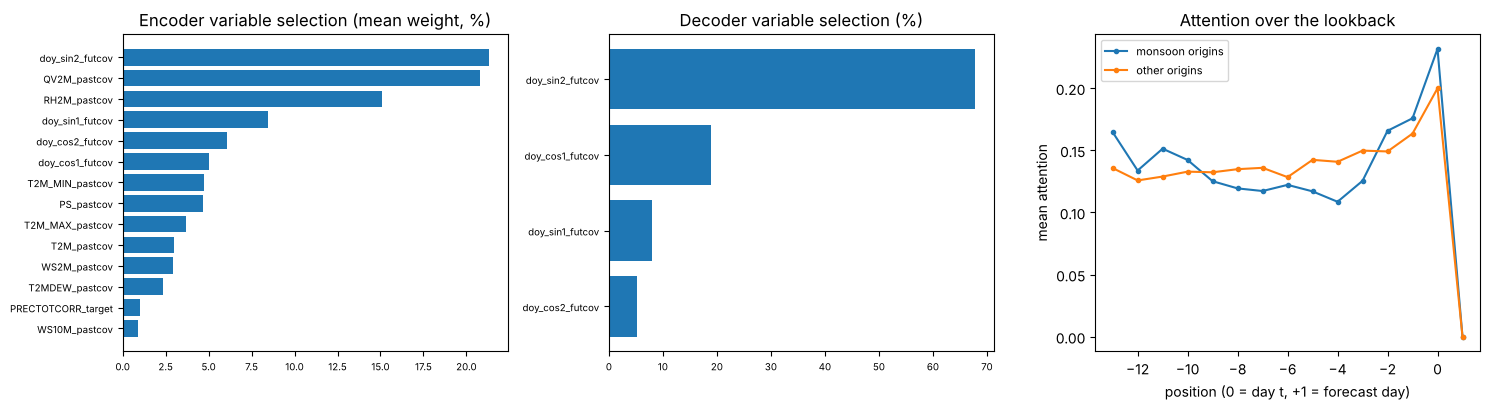

top encoder variables: {'doy_sin2_futcov': 21.299999237060547, 'QV2M_pastcov': 20.799999237060547, 'RH2M_pastcov': 15.100000381469727, 'doy_sin1_futcov': 8.5, 'doy_cos2_futcov': 6.099999904632568}
attention on day t (pos 0): 0.21 | on day t-1: 0.168 | on forecast day: 0.0 | uniform would be 0.067


In [6]:
from darts.explainability import TFTExplainer
d = tft_data
ex = TFTExplainer(tft_model, background_series=D.upto(d["target"], D.TRAIN_LAST), background_past_covariates=d["past"],
                  background_future_covariates=d["future"])
origins = pd.date_range("2015-01-10", "2019-12-15", freq="15D")
expl = ex.explain(foreground_series=[D.upto(d["target"], o) for o in origins],
                  foreground_past_covariates=[d["past"]] * len(origins), foreground_future_covariates=[d["future"]] * len(origins))
enc = pd.concat(expl.get_encoder_importance(), ignore_index=True)
dec = pd.concat(expl.get_decoder_importance(), ignore_index=True)
att = np.vstack([a.values()[:, 0] for a in expl.get_attention()])          # (origins, 15 positions)
monsoon = origins.month.isin([6, 7, 8, 9])
imp = enc.mean().sort_values(ascending=False)
pd.DataFrame({"encoder_mean": enc.mean(), "encoder_std": enc.std()}).sort_values("encoder_mean", ascending=False).round(2).to_csv(TAB / "05_tft_encoder_importance.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].barh(imp.index[::-1], imp.values[::-1]); axes[0].set(title="Encoder variable selection (mean weight, %)")
axes[1].barh(dec.mean().sort_values().index, dec.mean().sort_values().values); axes[1].set(title="Decoder variable selection (%)")
pos = np.arange(-13, 2)
for m, lab in ((monsoon, "monsoon origins"), (~monsoon, "other origins")):
    axes[2].plot(pos, att[m].mean(0), "o-", ms=3, label=lab)
axes[2].set(xlabel="position (0 = day t, +1 = forecast day)", ylabel="mean attention", title="Attention over the lookback")
axes[2].legend(fontsize=8)
for a in axes[:2]: a.tick_params(labelsize=7)
fig.tight_layout(); save(fig, "05_tft_explainability.png"); plt.show()
print("top encoder variables:", imp.head(5).round(1).to_dict())
print("attention on day t (pos 0):", att[:, 13].mean().round(3), "| on day t-1:", att[:, 12].mean().round(3),
      "| on forecast day:", att[:, 14].mean().round(3), "| uniform would be", round(1 / 15, 3))

**Interpretation:**
- **What the variable-selection network (VSN) used:** the top encoder variables are a seasonal harmonic (doy_sin2, 21 %), specific humidity QV2M (21 %), relative humidity RH2M (15 %) and two more harmonics (≈ 15 % together). Rain history is not at the top. This differs from the boosters, where same-day rain dominated permutation importance (Stage 4, DECISIONS 4.17).
- **What attention looked at:** day t received 0.21 and day t−1 0.17, against 0.067 for uniform attention. The forecast-day position received 0.0, as expected, since only calendar covariates are known there.

**Over-interpretation warning.**
1. VSN weights are *gates inside one network*, not causal effects or marginal predictive value. Near-surface humidity rises with recent rain, so the network can route rain information through QV2M/RH2M; a low weight for rain does **not** mean rain history is unimportant.
2. The weights come from **one seed** and averaged training windows; they are not stable across seeds or seasons.
3. Attention weights are known to be unreliable as explanations (Jain & Wallace, 2019); here they only confirm "recent days matter most", which a lag-1 baseline already tells us.

**Decision:** report the VSN and attention as *descriptive* (what the model attends to), never as evidence about atmospheric drivers.

**Paper note:** *The TFT's variable-selection weights emphasised humidity and seasonal harmonics and its attention concentrated on the two most recent days; these weights describe the fitted network rather than physical causation and should be interpreted with caution.*

# Part 2 — Prompt 5.5: rain / no-rain from the deep models

### Step 7 — Three ways to get a rain probability, and what darts supports (rule 13)

| option | how | limitations |
|---|---|---|
| **1** (all models) | the regression forecast (mm) is a score: (a) **raw** — yes/no if forecast ≥ a mm threshold chosen on the 2012–2014 slice (max CSI); (b) **Platt** — logistic regression on log1p(score) fitted on the slice; (c) **isotonic** — monotone step function fitted on the slice | (a) gives no probabilities (no Brier/BSS/ECE); (b)/(c) are only as good as the ranking of the score, and the calibration is learnt on 2012–2014, i.e. before the 2016 regime shift |
| **2** (TFT) | P(rain ≥ 1 mm) = 1 − F̂(1 mm), F̂ interpolated linearly through the 7 predicted quantiles; also isotonic-calibrated on the slice | the predicted CDF is only known at 7 points; outside q0.05–q0.95 the probability is clamped to [0.05, 0.95]; rain has a point mass at 0 that quantiles describe poorly |
| **3** (all models) | **darts `BernoulliLikelihood`** on a binary target series (rain ≥ 1 mm), with today's log rain added as a past covariate; raw and isotonic | a separate model per task; the binary history alone throws away amounts (hence the extra covariate) |

**Rule-13 check:** darts 0.48.0 ships `BernoulliLikelihood` (`darts.utils.likelihood_models`), and TSMixer, TiDE and TFT all accept a
`likelihood` argument; a smoke test confirmed that all three train on a 0/1 series and return a probability component (`wet_p`). Option 3 is
therefore supported **natively** and is run below.

All thresholds (max CSI) and calibration mappings are fitted **only on the 2012–2014 slice forecasts of the inner models**; validation is scored.

**Look for (next step):** run times of the Bernoulli models.

In [7]:
t0 = time.time()
for kind in ("tsmixer", "tide", "tft"):
    for seed in SEEDS:
        run_and_score(kind, "bin", L, seed)
print(f"total {time.time() - t0:.0f}s")

tsmixer bin L=14 seed 0: {'mean p': np.float32(0.534)} | best epoch 29 | 48s


tsmixer bin L=14 seed 1: {'mean p': np.float32(0.535)} | best epoch 42 | 68s


tsmixer bin L=14 seed 2: {'mean p': np.float32(0.522)} | best epoch 21 | 39s


tsmixer bin L=14 seed 3: {'mean p': np.float32(0.536)} | best epoch 26 | 43s


tsmixer bin L=14 seed 4: {'mean p': np.float32(0.549)} | best epoch 22 | 38s


...

tft     bin L=14 seed 1: {'mean p': np.float32(0.559)} | best epoch 16 | 183s


tft     bin L=14 seed 2: {'mean p': np.float32(0.559)} | best epoch 23 | 252s


tft     bin L=14 seed 3: {'mean p': np.float32(0.54)} | best epoch 22 | 248s


tft     bin L=14 seed 4: {'mean p': np.float32(0.575)} | best epoch 29 | 331s


total 1943s


**Interpretation:** rule 13 check: darts 0.48 provides `BernoulliLikelihood` natively, and all three models trained with it.
- Mean predicted P(wet) is 0.52–0.58, close to the validation wet-day frequency, so the probabilities are not shifted.
- **TiDE stopped at epoch 60 in all five seeds.** That is the epoch cap, so validation loss was still improving and TiDE-Bernoulli is under-trained under our fixed budget.
- TSMixer stopped at epoch 21–42 and TFT at epoch 10–29.

**Decision:** keep the fixed 60-epoch budget so the protocol stays identical across models (rule 7). We disclose TiDE's under-training as a limitation rather than tuning it on validation results. Raising the cap is a candidate for Stage 6.

**Paper note:** *Bernoulli-likelihood variants were trained natively in Darts; TiDE reached the 60-epoch cap in every seed, so its classification skill should be regarded as a lower bound.*

### Step 8 — Classification scores of all deep options

**WHAT:** for every deep run at L = 14 (TSMixer/TiDE mm and log targets, TFT quantiles, three Bernoulli models; seeds 0–4) compute all options and
score them with the same function as the classical models (ROC-AUC, PR-AUC, Brier, BSS vs climatology, BSS vs seasonal + persistence, ECE,
POD, FAR, CSI, HSS, monsoon ROC-AUC); thresholds from the slice.

**WHY:** one table to see which route to a probability works best.

**Look for:** BSS and ECE of the calibrated options vs the classification references; whether option 2/3 beat option 1.

In [8]:
rows = []
for kind, transforms in (("tsmixer", ("mm", "log", "bin")), ("tide", ("mm", "log", "bin")), ("tft", ("mm", "bin"))):
    for transform in transforms:
        for seed in SEEDS:
            rows.append(DC.evaluate(kind, transform, seed, REFS_CLS))
cls_res = pd.concat(rows); DC.store(cls_res)
CK = ["ROC_AUC", "PR_AUC", "Brier", "BSS", "BSS_vs_seas_pers", "ECE", "recall_POD", "FAR", "CSI", "HSS", "ROC_AUC_monsoon"]
g = cls_res[cls_res.metric.isin(CK)].groupby(["model", "target", "option", "metric"])["value"]
deep_cls = (g.mean().map("{:.3f}".format) + " ± " + g.std().fillna(0).map("{:.3f}".format)).unstack("metric")[CK]
deep_cls = deep_cls.loc[g.mean().unstack("metric")["CSI"].sort_values(ascending=False).index]
deep_cls.to_csv(TAB / "05_deep_classification_L14.csv")
display(deep_cls)
va, yc, refs = REFS_CLS
pd.DataFrame({k: E.score("cls", yc, refs[k], 0.5, refs, va) for k in ("seasonal+persistence", "climatology", "persistence")}).T[CK].round(3)

metric                              ROC_AUC         PR_AUC          Brier            BSS BSS_vs_seas_pers            ECE     recall_POD            FAR            CSI            HSS ROC_AUC_monsoon
model   target option                                                                                                                                                                               
tft     bin    opt3_isotonic  0.964 ± 0.001  0.967 ± 0.001  0.070 ± 0.002  0.298 ± 0.021    0.096 ± 0.027  0.032 ± 0.010  0.931 ± 0.018  0.085 ± 0.019  0.856 ± 0.003  0.815 ± 0.007   0.830 ± 0.005
               opt3_raw       0.965 ± 0.001  0.972 ± 0.002  0.069 ± 0.002  0.307 ± 0.018    0.107 ± 0.023  0.035 ± 0.007  0.927 ± 0.015  0.081 ± 0.015  0.856 ± 0.003  0.816 ± 0.007   0.828 ± 0.007
tsmixer bin    opt3_isotonic  0.963 ± 0.002  0.967 ± 0.002  0.072 ± 0.002  0.271 ± 0.016    0.061 ± 0.021  0.045 ± 0.012  0.926 ± 0.011  0.083 ± 0.008  0.854 ± 0.005  0.814 ± 0.006   0.831 ± 0.013
               opt3_raw       0.964 ± 0.002  0.971 ± 0.002  0.072 ± 0.002  0.279 ± 0.018    0.070 ± 0.023  0.043 ± 0.007  0.926 ± 0.010  0.083 ± 0.007  0.854 ± 0.005  0.813 ± 0.007   0.833 ± 0.009
        log    opt1_isotonic  0.962 ± 0.001  0.965 ± 0.001  0.073 ± 0.004  0.260 ± 0.038    0.047 ± 0.049  0.046 ± 0.016  0.926 ± 0.013  0.084 ± 0.015  0.853 ± 0.005  0.812 ± 0.009   0.806 ± 0.006
               opt1_platt     0.964 ± 0.001  0.970 ± 0.001  0.074 ± 0.005  0.250 ± 0.054    0.033 ± 0.069  0.050 ± 0.017  0.925 ± 0.013  0.083 ± 0.014  0.853 ± 0.004  0.812 ± 0.007   0.820 ± 0.012
               opt1_raw       0.964 ± 0.001  0.970 ± 0.001            NaN            NaN              NaN            NaN  0.923 ± 0.013  0.082 ± 0.014  0.852 ± 0.005  0.811 ± 0.008   0.820 ± 0.012
tft     mm     opt1_platt     0.961 ± 0.001  0.967 ± 0.001  0.072 ± 0.001  0.272 ± 0.015    0.062 ± 0.019  0.040 ± 0.010  0.910 ± 0.017  0.072 ± 0.017  0.850 ± 0.001  0.812 ± 0.004   0.796 ± 0.005
               opt1_isotonic  0.959 ± 0.002  0.960 ± 0.002  0.073 ± 0.002  0.263 ± 0.018    0.051 ± 0.023  0.037 ± 0.013  0.906 ± 0.020  0.067 ± 0.019  0.850 ± 0.002  0.813 ± 0.003   0.786 ± 0.009
               opt1_raw       0.961 ± 0.001  0.967 ± 0.001            NaN            NaN              NaN            NaN  0.909 ± 0.017  0.071 ± 0.017  0.850 ± 0.002  0.811 ± 0.004   0.796 ± 0.005
               opt2_isotonic  0.959 ± 0.002  0.959 ± 0.002  0.073 ± 0.003  0.260 ± 0.031    0.047 ± 0.040  0.040 ± 0.016  0.905 ± 0.017  0.067 ± 0.015  0.849 ± 0.003  0.812 ± 0.003   0.783 ± 0.013
               opt2_raw       0.961 ± 0.002  0.964 ± 0.002  0.073 ± 0.003  0.261 ± 0.028    0.047 ± 0.036  0.058 ± 0.009  0.905 ± 0.017  0.067 ± 0.016  0.849 ± 0.003  0.812 ± 0.003   0.790 ± 0.011
tsmixer mm     opt1_platt     0.956 ± 0.001  0.964 ± 0.002  0.077 ± 0.002  0.226 ± 0.023    0.002 ± 0.030  0.050 ± 0.008  0.903 ± 0.012  0.070 ± 0.010  0.846 ± 0.004  0.807 ± 0.005   0.773 ± 0.008
               opt1_isotonic  0.955 ± 0.001  0.958 ± 0.001  0.078 ± 0.003  0.211 ± 0.026   -0.017 ± 0.033  0.047 ± 0.009  0.903 ± 0.012  0.070 ± 0.010  0.846 ± 0.004  0.807 ± 0.005   0.772 ± 0.009
               opt1_raw       0.956 ± 0.001  0.964 ± 0.002            NaN            NaN              NaN            NaN  0.902 ± 0.012  0.070 ± 0.010  0.845 ± 0.003  0.806 ± 0.003   0.773 ± 0.008
tide    log    opt1_platt     0.957 ± 0.000  0.968 ± 0.000  0.075 ± 0.000  0.244 ± 0.001    0.025 ± 0.001  0.027 ± 0.001  0.914 ± 0.006  0.084 ± 0.005  0.843 ± 0.001  0.800 ± 0.000   0.841 ± 0.000
               opt1_raw       0.957 ± 0.000  0.968 ± 0.000            NaN            NaN              NaN            NaN  0.914 ± 0.005  0.085 ± 0.004  0.843 ± 0.001  0.800 ± 0.001   0.841 ± 0.000
               opt1_isotonic  0.956 ± 0.000  0.963 ± 0.001  0.074 ± 0.000  0.250 ± 0.002    0.033 ± 0.003  0.011 ± 0.002  0.914 ± 0.004  0.085 ± 0.003  0.842 ± 0.001  0.799 ± 0.002   0.836 ± 0.005
        bin    opt3_raw       0.947 ± 0.000  0.952 ± 0.000  

,ROC_AUC,PR_AUC,Brier,BSS,BSS_vs_seas_pers,ECE,recall_POD,FAR,CSI,HSS,ROC_AUC_monsoon
seasonal+persistence,0.959,0.963,0.077,0.224,0.000,0.059,0.888,0.065,0.836,0.797,0.789
climatology,0.944,0.957,0.099,0.000,-0.288,0.099,0.836,0.061,0.793,0.748,0.765
persistence,0.898,0.884,0.093,0.062,-0.209,0.056,0.913,0.087,0.840,0.796,0.730


**Interpretation:** (BSS vs climatology; seasonal + persistence has BSS 0.224, ROC-AUC 0.959, CSI 0.836, ECE 0.059)
- **Option 3 (Bernoulli) is the best route.**
  - TFT bin raw: BSS 0.307 ± 0.018, BSS vs seasonal + persistence +0.107, ROC-AUC 0.965, CSI 0.856, ECE 0.035.
  - TSMixer bin raw: 0.279.
  - The model is trained on the quantity it is scored on, so it learns P(wet) directly. Isotonic recalibration on the slice does not help (TFT 0.298) because the raw probabilities are already calibrated.
- **Option 1 (calibrated mm forecast) is the second best** (TFT Platt 0.272, TSMixer log isotonic 0.260, TiDE log isotonic 0.250 with the best ECE, 0.011). It inherits the weaknesses of the regression model it calibrates: TiDE mm gives BSS of only 0.08–0.11. Option 1 *raw* gives a yes/no forecast only, so it has CSI but no Brier/BSS.
- **Option 2 (P from TFT quantiles) gives 0.261.** It is limited by two things:
  - Only seven quantile knots, so the CDF at 1 mm is interpolated.
  - The [0.05, 0.95] clamp, which forbids confident forecasts on clearly dry or clearly wet days and caps the Brier score.
  - In addition, the zero point mass (many quantiles exactly 0) is not resolved.
- All options have ROC-AUC 0.96–0.97: **ranking** is easy and almost identical. The differences are in **calibration and sharpness**, which Brier/BSS reward.

**Decision:** the master table and bootstrap keep **all** deep options, labelled, so nothing is hidden. In the text, the deep model's headline route is option 3 (Bernoulli), chosen because it trains on the scored quantity, not because it scored best on validation. Full results are in `05_deep_classification_L14.csv`.

**Paper note:** *Training the deep models directly with a Bernoulli likelihood gave better probabilistic forecasts (TFT BSS 0.31) than deriving probabilities from their rainfall-amount forecasts (BSS 0.25–0.27).*

### Step 9 — Reliability of the deep rain probabilities

**WHAT:** reliability diagram (seed 0) for TFT option 2 raw vs isotonic, the best option-1 calibration and the Bernoulli models.

**WHY:** a calibrated forecast is what a user can act on ("70 % chance of rain").

**Look for:** raw option-2 probabilities bounded to [0.05, 0.95]; isotonic curves close to the diagonal.

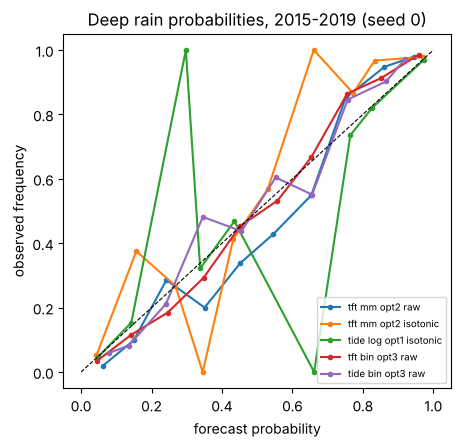

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.6))
for f in ("tft_mm_opt2_raw", "tft_mm_opt2_isotonic", "tide_log_opt1_isotonic", "tft_bin_opt3_raw", "tide_bin_opt3_raw"):
    o = pd.read_parquet(DC.PRED_DIR / f"{f}__seed0.parquet"); c = M.calibration(o["y_true"], o["pred"])
    ax.plot(c["mean_predicted"], c["observed_frequency"], "o-", ms=3, label=f.replace("_", " "))
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set(xlabel="forecast probability", ylabel="observed frequency",
                                               title="Deep rain probabilities, 2015-2019 (seed 0)"); ax.legend(fontsize=7)
save(fig, "05_deep_reliability.png"); plt.show()

**Interpretation:**
- **TFT Bernoulli raw (red) follows the diagonal across all bins.** It is the best-calibrated curve without any post-processing. TiDE Bernoulli raw (purple) is similar, but noisier in the middle.
- **TFT option 2 raw (blue)** has no forecasts below about 0.05 or above 0.95 (the clamp). Between 0.35 and 0.65 it lies *below* the diagonal, i.e. it over-forecasts rain at intermediate probabilities, and it is slightly under-confident above 0.75.
- **The isotonic curves (orange, green) zig-zag.** Isotonic regression outputs a step function with few distinct values, so some middle bins hold only a handful of days. Single points at 0 or 1 there are small-sample noise. ECE weights bins by their number of days, which is why TiDE log + isotonic still has the lowest ECE (0.011): almost all of its forecasts sit near 0 or 1, where it is well calibrated.
- **Lesson:** a reliability diagram should be read together with the number of forecasts per bin.

**Decision:** option 3 is confirmed as the preferred deep probability route. ECE is reported alongside BSS, and the paper figure will add a forecast-count histogram (planned for Stage 7).

**Paper note:** *Bernoulli-trained TFT probabilities were well calibrated without post-processing, whereas probabilities derived from the predicted quantiles over-forecast rain at intermediate probability levels.*

# Part 3 — Prompt 5.6: apples-to-apples comparison

### Step 10 — Classical models and baselines on exactly the same split

**WHAT:** `experiment.run_cv(..., split="dl")` refits every classical configuration (Set B; the 10 playbook families for both tasks; stochastic
models with seeds 0–4) and the regression finalists (CatBoost Tweedie, hurdle CatBoost direct/log, CatBoost log target) with training targets
1981–2014, the inner slice 2012–2014 (early stopping, smearing, thresholds) and validation 2015–2019. Baselines are refitted on the same rows.

**WHY:** approved decision — the only fair comparison with the deep models is on identical training data, slice and validation days.

**Look for:** run times; no errors.

In [10]:
t0 = time.time()
for task in ("cls", "reg"):
    E.run_baselines(task, split="dl")
CLS10 = {**{k: v for k, v in Mo.LINEAR_CLS.items()}, **{k: (f, True) for k, f in Mo.trees("cls").items()}, "mlp": (Mo.mlp("cls"), True)}
REG10 = {**{k: v for k, v in Mo.LINEAR_REG.items()}, **{k: (f, True) for k, f in Mo.trees("reg").items()},
         **{f"mlp_{l}": (Mo.mlp("reg", l), True) for l in ("huber", "mae", "mse")},
         **{k: (f, True) for k, f in Mo.tweedie().items()}}
for task, specs in (("cls", CLS10), ("reg", REG10)):
    for name, (factory, stochastic) in specs.items():
        for seed in (SEEDS if stochastic else [0]):
            E.run_cv(name, factory, task, "B", seed, split="dl")
        print(f"{task} {name}: done ({time.time() - t0:.0f}s)", flush=True)
cat_reg = Mo.trees("reg")["catboost"]
for seed in SEEDS:
    RV.run_hurdle("catboost", cat_reg, "B", seed, split="dl"); RV.run_log("catboost", cat_reg, "B", seed, split="dl")
print(f"variants done ({time.time() - t0:.0f}s)")

cls logreg_none: done (17s)


cls logreg_l2: done (23s)


cls logreg_l1: done (71s)


cls logreg_enet: done (103s)


cls sgd_logloss: done (107s)


...

reg mlp_mse: done (516s)


reg xgboost_tweedie: done (528s)


reg lightgbm_tweedie: done (537s)


reg catboost_tweedie: done (559s)


variants done (617s)


**Interpretation:** all 10 classical families (classification and regression), the three Tweedie boosters, the log variants and the
hurdle models were refit on exactly the DL split in about 10 minutes in total. That is less than **one** TFT seed at L = 60. Every
booster used the same 2012–2014 slice for early stopping, smearing and thresholds as the deep models.

**Decision:** the comparison is now apples-to-apples. All models share the same training years (≤ 2014), the same slice, the same 1,826 validation days, the same references and the same metric code.

**Paper note:** *For the final comparison, all classical models were re-trained on the identical chronological split used for the deep models (training ≤ 2014, early-stopping slice 2012–2014, validation 2015–2019).*

### Step 11 — Master tables (validation 2015–2019): baselines, 10 classical, 3 deep

**WHAT:** mean ± std over seeds for every configuration. Classification ranked by **BSS** (approved primary), regression by **MAE**
(approved primary) — MSESS, RMSE and bias alongside.

**WHY:** the single table for the paper; all rows were produced on identical data with identical metric code.

**Look for:** where the deep models rank; whether the classical ranking of Stage 4 (CV folds) is reproduced on this split.

In [11]:
U = C.unified_results()
CLS_KEY = ["BSS", "BSS_vs_seas_pers", "PR_AUC", "ROC_AUC", "ROC_AUC_monsoon", "ECE", "CSI", "HSS"]
REG_KEY = ["MAE", "MSESS", "MSESS_vs_seas_pers", "RMSE", "bias", "MAE_wet", "recall_ge20", "recall_ge50"]
master_cls = C.summary(U[~U.model.str.contains("opt1_raw")], "cls", CLS_KEY, "BSS", ascending=False)
master_reg = C.summary(U, "reg", REG_KEY, "MAE", ascending=True)
master_cls.to_csv(TAB / "05_master_classification_dl.csv"); master_reg.to_csv(TAB / "05_master_regression_dl.csv")
display(master_cls)
master_reg

metric                                              BSS BSS_vs_seas_pers         PR_AUC        ROC_AUC ROC_AUC_monsoon            ECE            CSI            HSS  n_seeds
family    model                                                                                                                                                             
classical lightgbm (B)                    0.328 ± 0.002    0.134 ± 0.002  0.974 ± 0.000  0.967 ± 0.000   0.848 ± 0.005  0.022 ± 0.002  0.860 ± 0.004  0.823 ± 0.005        5
          catboost (B)                    0.321 ± 0.006    0.125 ± 0.008  0.973 ± 0.001  0.966 ± 0.001   0.838 ± 0.011  0.025 ± 0.001  0.853 ± 0.008  0.815 ± 0.008        5
          xgboost (B)                     0.320 ± 0.003    0.124 ± 0.003  0.973 ± 0.001  0.966 ± 0.000   0.839 ± 0.008  0.025 ± 0.004  0.857 ± 0.003  0.819 ± 0.005        5
deep      tft bin opt3_raw                0.307 ± 0.018    0.107 ± 0.023  0.972 ± 0.002  0.965 ± 0.001   0.828 ± 0.007  0.035 ± 0.007  0.856 ± 0.003  0.816 ± 0.007        5
classical logreg_none (B)                 0.299 ± 0.000    0.097 ± 0.000  0.970 ± 0.000  0.963 ± 0.000   0.846 ± 0.000  0.014 ± 0.000  0.853 ± 0.000  0.813 ± 0.000        1
deep      tft bin opt3_isotonic           0.298 ± 0.021    0.096 ± 0.027  0.967 ± 0.001  0.964 ± 0.001   0.830 ± 0.005  0.032 ± 0.010  0.856 ± 0.003  0.815 ± 0.007        5
classical logreg_l1 (B)                   0.298 ± 0.000    0.096 ± 0.000  0.971 ± 0.000  0.963 ± 0.000   0.848 ± 0.000  0.024 ± 0.000  0.850 ± 0.000  0.811 ± 0.000        5
          logreg_l2 (B)                   0.297 ± 0.000    0.094 ± 0.000  0.970 ± 0.000  0.963 ± 0.000   0.847 ± 0.000  0.020 ± 0.000  0.856 ± 0.000  0.814 ± 0.000        1
          logreg_enet (B)                 0.295 ± 0.000    0.092 ± 0.000  0.970 ± 0.000  0.963 ± 0.000   0.845 ± 0.000  0.025 ± 0.000  0.849 ± 0.000  0.810 ± 0.000        5
          mlp (B)                         0.287 ± 0.014    0.081 ± 0.018  0.970 ± 0.001  0.963 ± 0.001   0.827 ± 0.009  0.028 ± 0.004  0.848 ± 0.002  0.802 ± 0.005        5
deep      tsmixer bin opt3_raw            0.279 ± 0.018    0.070 ± 0.023  0.971 ± 0.002  0.964 ± 0.002   0.833 ± 0.009  0.043 ± 0.007  0.854 ± 0.005  0.813 ± 0.007        5
classical random_forest (B)               0.273 ± 0.003    0.063 ± 0.003  0.970 ± 0.001  0.964 ± 0.000   0.804 ± 0.006  0.054 ± 0.001  0.848 ± 0.002  0.810 ± 0.002        5
deep      tft mm opt1_platt               0.272 ± 0.015    0.062 ± 0.019  0.967 ± 0.001  0.961 ± 0.001   0.796 ± 0.005  0.040 ± 0.010  0.850 ± 0.001  0.812 ± 0.004        5
          tsmixer bin opt3_isotonic       0.271 ± 0.016    0.061 ± 0.021  0.967 ± 0.002  0.963 ± 0.002   0.831 ± 0.013  0.045 ± 0.012  0.854 ± 0.005  0.814 ± 0.006        5
          tft mm opt1_isotonic            0.263 ± 0.018    0.051 ± 0.023  0.960 ± 0.002  0.959 ± 0.002   0.786 ± 0.009  0.037 ± 0.013  0.850 ± 0.002  0.813 ± 0.003        5
          tft mm opt2_raw                 0.261 ± 0.028    0.047 ± 0.036  0.964 ± 0.002  0.961 ± 0.002   0.790 ± 0.011  0.058 ± 0.009  0.849 ± 0.003  0.812 ± 0.003        5
          tft mm opt2_isotonic            0.260 ± 0.031    0.047 ± 0.040  0.959 ± 0.002  0.959 ± 0.002   0.783 ± 0.013  0.040 ± 0.016  0.849 ± 0.003  0.812 ± 0.003        5
          tsmixer log opt1_isotonic       0.260 ± 0.038    0.047 ± 0.049  0.965 ± 0.001  0.962 ± 0.001   0.806 ± 0.006  0.046 ± 0.016  0.853 ± 0.005  0.812 ± 0.009        5
          tsmixer log opt1_platt          0.250 ± 0.054    0.033 ± 0.069  0.970 ± 0.001  0.964 ± 0.001   0.820 ± 0.012  0.050 ± 0.017  0.853 ± 0.004  0.812 ± 0.007        5
          tide log opt1_isotonic          0.250 ± 0.002    0.033 ± 0.003  0.963 ± 0.001  0.956 ± 0.000   0.836 ± 0.005  0.011 ± 0.002  0.842 ± 0.001  0.799 ± 0.002        5
classical sgd_logloss (B)                 0.246 ± 0.072    0.028 ± 0.092  0.964 ± 0.006  0.958 ± 0.007   0.850 ± 0.009  0.028 ± 0.016  0.839 ± 0.016  0.789 ± 0.031        5
deep      tide log op

metric                                              MAE           MSESS MSESS_vs_seas_pers            RMSE            bias         MAE_wet    recall_ge20    recall_ge50  n_seeds
family    model                                                                                                                                                                  
classical hurdle_catboost_log (B)         8.879 ± 0.047   0.369 ± 0.005      0.040 ± 0.008  18.344 ± 0.075  -3.805 ± 0.072  14.349 ± 0.081  0.519 ± 0.008  0.103 ± 0.007        5
          catboost+log_smear (B)          8.973 ± 0.070   0.329 ± 0.013     -0.021 ± 0.020  18.920 ± 0.187  -4.917 ± 0.159  14.623 ± 0.121  0.457 ± 0.015  0.056 ± 0.015        5
baseline  baseline:seasonal+persistence   9.019 ± 0.000   0.343 ± 0.000      0.000 ± 0.000  18.725 ± 0.000  -4.595 ± 0.000  14.585 ± 0.000  0.459 ± 0.000  0.152 ± 0.000        1
classical mlp_mse (B)                     9.113 ± 0.128   0.334 ± 0.042     -0.014 ± 0.063  18.846 ± 0.587  -4.303 ± 1.026  14.729 ± 0.322  0.509 ± 0.092  0.052 ± 0.038        5
          catboost (B)                    9.150 ± 0.030   0.310 ± 0.002     -0.051 ± 0.003  19.193 ± 0.027  -4.775 ± 0.038  14.830 ± 0.041  0.468 ± 0.009  0.005 ± 0.007        5
          catboost_tweedie (B)            9.158 ± 0.080   0.288 ± 0.014     -0.084 ± 0.021  19.491 ± 0.187  -5.337 ± 0.165  15.033 ± 0.133  0.424 ± 0.018  0.000 ± 0.000        5
          hurdle_catboost_direct (B)      9.167 ± 0.034   0.305 ± 0.005     -0.058 ± 0.007  19.264 ± 0.065  -4.880 ± 0.091  14.899 ± 0.056  0.455 ± 0.004  0.002 ± 0.003        5
          random_forest (B)               9.169 ± 0.025   0.333 ± 0.002     -0.016 ± 0.003  18.873 ± 0.029  -3.920 ± 0.047  14.688 ± 0.034  0.523 ± 0.004  0.005 ± 0.004        5
deep      tft qmean                       9.185 ± 0.082   0.280 ± 0.024     -0.096 ± 0.037  19.599 ± 0.327  -5.104 ± 0.771  14.979 ± 0.239  0.473 ± 0.068  0.000 ± 0.000        5
          tsmixer log_smear               9.195 ± 0.136   0.299 ± 0.025     -0.068 ± 0.039  19.347 ± 0.353  -5.962 ± 0.615  15.015 ± 0.326  0.370 ± 0.040  0.068 ± 0.029        5
          tide log_naive                  9.199 ± 0.031   0.283 ± 0.006     -0.091 ± 0.010  19.556 ± 0.089  -5.766 ± 0.133  15.322 ± 0.054  0.447 ± 0.016  0.082 ± 0.006        5
classical xgboost (B)                     9.215 ± 0.057   0.316 ± 0.007     -0.040 ± 0.011  19.100 ± 0.102  -4.596 ± 0.167  14.839 ± 0.082  0.466 ± 0.014  0.012 ± 0.009        5
          lightgbm (B)                    9.232 ± 0.095   0.310 ± 0.009     -0.050 ± 0.014  19.187 ± 0.131  -4.729 ± 0.134  14.876 ± 0.106  0.451 ± 0.020  0.020 ± 0.004        5
deep      tsmixer mm                      9.236 ± 0.268   0.307 ± 0.027     -0.055 ± 0.042  19.227 ± 0.383  -5.030 ± 0.470  14.779 ± 0.277  0.444 ± 0.037  0.000 ± 0.000        5
classical mlp_huber (B)                   9.396 ± 0.352   0.252 ± 0.067     -0.138 ± 0.102  19.963 ± 0.884  -6.247 ± 0.987  15.453 ± 0.716  0.328 ± 0.107  0.024 ± 0.028        5
          linreg (B)                      9.407 ± 0.000   0.286 ± 0.000     -0.087 ± 0.000  19.519 ± 0.000  -4.438 ± 0.000  14.976 ± 0.000  0.505 ± 0.000  0.000 ± 0.000        1
          ridge (B)                       9.409 ± 0.000   0.286 ± 0.000     -0.087 ± 0.000  19.524 ± 0.000  -4.449 ± 0.000  14.980 ± 0.000  0.508 ± 0.000  0.000 ± 0.000        1
deep      tide log_smear                  9.434 ± 0.047   0.398 ± 0.001      0.084 ± 0.001  17.922 ± 0.014  -0.738 ± 0.195  14.993 ± 0.081  0.724 ± 0.006  0.233 ± 0.008        5
classical xgboost_tweedie (B)             9.447 ± 0.045   0.234 ± 0.006     -0.166 ± 0.009  20.224 ± 0.081  -6.165 ± 0.073  15.561 ± 0.071  0.343 ± 0.015  0.000 ± 0.000        5
          lightgbm_tweedie (B)            9.488 ± 0.036   0.225 ± 0.004     -0.180 ± 0.006  20.337 ± 0.049  -6.184 ± 0.051  15.615 ± 0.052  0.342 ± 0.009  0.000 ± 0.000        5
          mlp_mae (B)                     9.511 ± 0.218   0.210 ± 0.036     -0.203 ±

**Interpretation:**
- **Classification (BSS):** the three boosters lead (LightGBM 0.328, CatBoost 0.321, XGBoost 0.320), followed by TFT Bernoulli (0.307). Next come the four logistic regressions (0.295–0.299) and the MLP (0.287). TSMixer Bernoulli (0.279), random forest (0.273) and SGD (0.246 ± 0.072, unstable) are lower. The best deep model sits between the boosters and logistic regression.
- **Regression:**
  - **MAE:** only the hurdle CatBoost (log + smearing) beats seasonal + persistence (MAE 8.88 vs 9.02). Most models cluster at 9.1–9.5 mm, deep and classical alike.
  - **MSESS:** TiDE log + smearing is best (0.398, bias only −0.74 mm, recall≥50 0.23), followed by TiDE mm (0.370) and the hurdle model (0.369). TiDE log + smearing has a mediocre MAE (9.43).
- **No model dominates.** MAE rewards forecasting the typical (low) amount; MSE rewards getting the heavy days right. A model can win one metric and lose the other.
- Classical models also rank similarly to Stage 4 cross-validation (boosters on top, linear models competitive for classification), so the DL split did not change the story.

**Decision:** report both MAE and MSESS (plus bias and heavy-rain recall) in the paper. Use the significance tests in Step 12 to decide which differences are real.

**Paper note:** *On the common validation period, gradient-boosted trees achieved the highest Brier skill (0.32–0.33), while for rainfall amounts the ranking depended on the metric: a hurdle CatBoost model minimised MAE and TiDE minimised MSE.*

### Step 12 — Paired block-bootstrap differences

**WHAT:** for every model, the difference to (i) seasonal + persistence and (ii) the best classical model, with 95 % CIs from 1,000
resamples of calendar months (target dates): **ΔBSS** for classification (references: seasonal + persistence, CatBoost, logreg_l1), **ΔMAE**
and **ΔMSESS** for regression (references: seasonal + persistence, CatBoost Tweedie). Seed-0 forecasts are used so each comparison is between
two concrete forecasts on the same resampled months (paired); "significant" = CI excludes 0.

**WHY:** with ~60 monthly blocks, many apparent differences are noise; pairing removes the shared month-to-month variation.

**Look for:** which deep models are significantly better or worse than the references.

In [12]:
pc = C.paired("cls", ["baseline:seasonal+persistence", "catboost (B)", "logreg_l1 (B)"])
pr = C.paired("reg", ["baseline:seasonal+persistence", "catboost_tweedie (B)"])
pc.to_csv(TAB / "05_paired_bootstrap_cls.csv", index=False); pr.to_csv(TAB / "05_paired_bootstrap_reg.csv", index=False)
show = lambda p, metric, ref: (p[(p.metric == metric) & (p.reference == ref)].sort_values("estimate", ascending=metric == "dMAE")
                               .set_index("model")[["estimate", "ci_low", "ci_high", "significant"]].round(3))
display(show(pc, "dBSS", "baseline:seasonal+persistence").head(25))
display(show(pc, "dBSS", "catboost (B)").head(25))
display(show(pr, "dMAE", "baseline:seasonal+persistence").head(25))
show(pr, "dMSESS", "catboost_tweedie (B)").sort_values("estimate", ascending=False).head(25)

,estimate,ci_low,ci_high,significant
model,,,,
lightgbm (B),0.106,0.061,0.148,True
catboost (B),0.101,0.061,0.141,True
tft bin opt3_raw,0.096,0.056,0.128,True
xgboost (B),0.095,0.053,0.139,True
tft bin opt3_isotonic,0.081,0.043,0.112,True
logreg_none (B),0.075,0.028,0.123,True
logreg_l1 (B),0.074,0.025,0.120,True
logreg_l2 (B),0.073,0.024,0.121,True
sgd_logloss (B),0.072,0.021,0.121,True


,estimate,ci_low,ci_high,significant
model,,,,
lightgbm (B),0.004,-0.013,0.020,False
tft bin opt3_raw,-0.005,-0.032,0.017,False
xgboost (B),-0.006,-0.022,0.009,False
tft bin opt3_isotonic,-0.021,-0.046,0.005,False
logreg_none (B),-0.026,-0.063,0.005,False
logreg_l1 (B),-0.027,-0.059,-0.000,True
logreg_l2 (B),-0.028,-0.064,0.003,False
sgd_logloss (B),-0.029,-0.071,0.007,False
logreg_enet (B),-0.030,-0.065,-0.001,True


,estimate,ci_low,ci_high,significant
model,,,,
hurdle_catboost_log (B),-0.210,-0.389,-0.033,True
catboost+log_smear (B),-0.059,-0.273,0.131,False
mlp_huber (B),0.002,-0.189,0.213,False
mlp_mse (B),0.024,-0.161,0.213,False
catboost_tweedie (B),0.068,-0.163,0.320,False
tsmixer log_smear,0.072,-0.118,0.257,False
tft qmean,0.096,-0.170,0.387,False
catboost (B),0.122,-0.074,0.336,False
hurdle_catboost_direct (B),0.127,-0.064,0.342,False


,estimate,ci_low,ci_high,significant
model,,,,
tide log_smear,0.098,0.033,0.155,True
hurdle_catboost_log (B),0.076,0.048,0.100,True
tide mm,0.072,0.011,0.126,True
baseline:seasonal+persistence,0.043,-0.006,0.089,False
random_forest (B),0.035,0.022,0.047,True
catboost+log_smear (B),0.035,0.010,0.059,True
mlp_mse (B),0.030,-0.002,0.056,False
mlp_huber (B),0.025,-0.010,0.059,False
tsmixer log_smear,0.016,-0.011,0.039,False


**Interpretation:** (paired monthly block bootstrap, seed-0 forecasts, 95 % CIs)
- **Classification vs seasonal + persistence:** LightGBM (+0.106), CatBoost (+0.101), TFT Bernoulli (+0.096), XGBoost (+0.095) and the logistic regressions (≈ +0.07) are all **significantly** better. MLP, TFT options 1/2 and TiDE options are not.
- **Classification vs CatBoost:** LightGBM +0.004, TFT Bernoulli −0.005 and XGBoost −0.006, all **not significant**. The best deep model is statistically tied with the best booster. logreg_l1 is significantly worse (−0.027), and so are most deep options.
- **Regression MAE vs seasonal + persistence:** only the hurdle CatBoost log model is significantly better (−0.21 mm, CI −0.39 to −0.03). TiDE log + smearing (+0.46) and LightGBM (+0.23) are significantly *worse*. Everything else is not significant.
- **Regression MSESS vs seasonal + persistence:** TiDE log + smearing (+0.054, CI 0.020–0.078), the hurdle model (+0.032) and TiDE mm (+0.029) are significantly better.
- **Regression vs CatBoost Tweedie:** the hurdle model is significantly better on MAE (−0.28). TiDE log + smearing is better on MSESS (+0.098).

**Caveat:** these CIs use **seed 0 only**. Seed variability (e.g. TSMixer ±0.27 MAE) is *not* included, so CIs for the stochastic deep models are too narrow. We have not corrected for multiple comparisons (~40 models × 2 references); individually "significant" results near the boundary should be read with care.

**Decision:** headline claims are limited to differences that are significant and also consistent with the seed-mean table: boosters ≈ TFT-Bernoulli > seasonal + persistence for classification; hurdle CatBoost best on MAE; TiDE best on MSE.

**Paper note:** *In paired block-bootstrap tests, the TFT with a Bernoulli likelihood was statistically indistinguishable from CatBoost in Brier skill (ΔBSS −0.005, n.s.), and only a hurdle CatBoost model significantly improved on the seasonal-plus-persistence baseline in MAE.*

### Step 13 — Comparison chart

**WHAT:** paired differences vs seasonal + persistence with 95 % CIs: ΔBSS (classification), ΔMAE and ΔMSESS (regression); colour = family.

**WHY:** the figure for the results section.

**Look for:** intervals entirely on the "better" side.

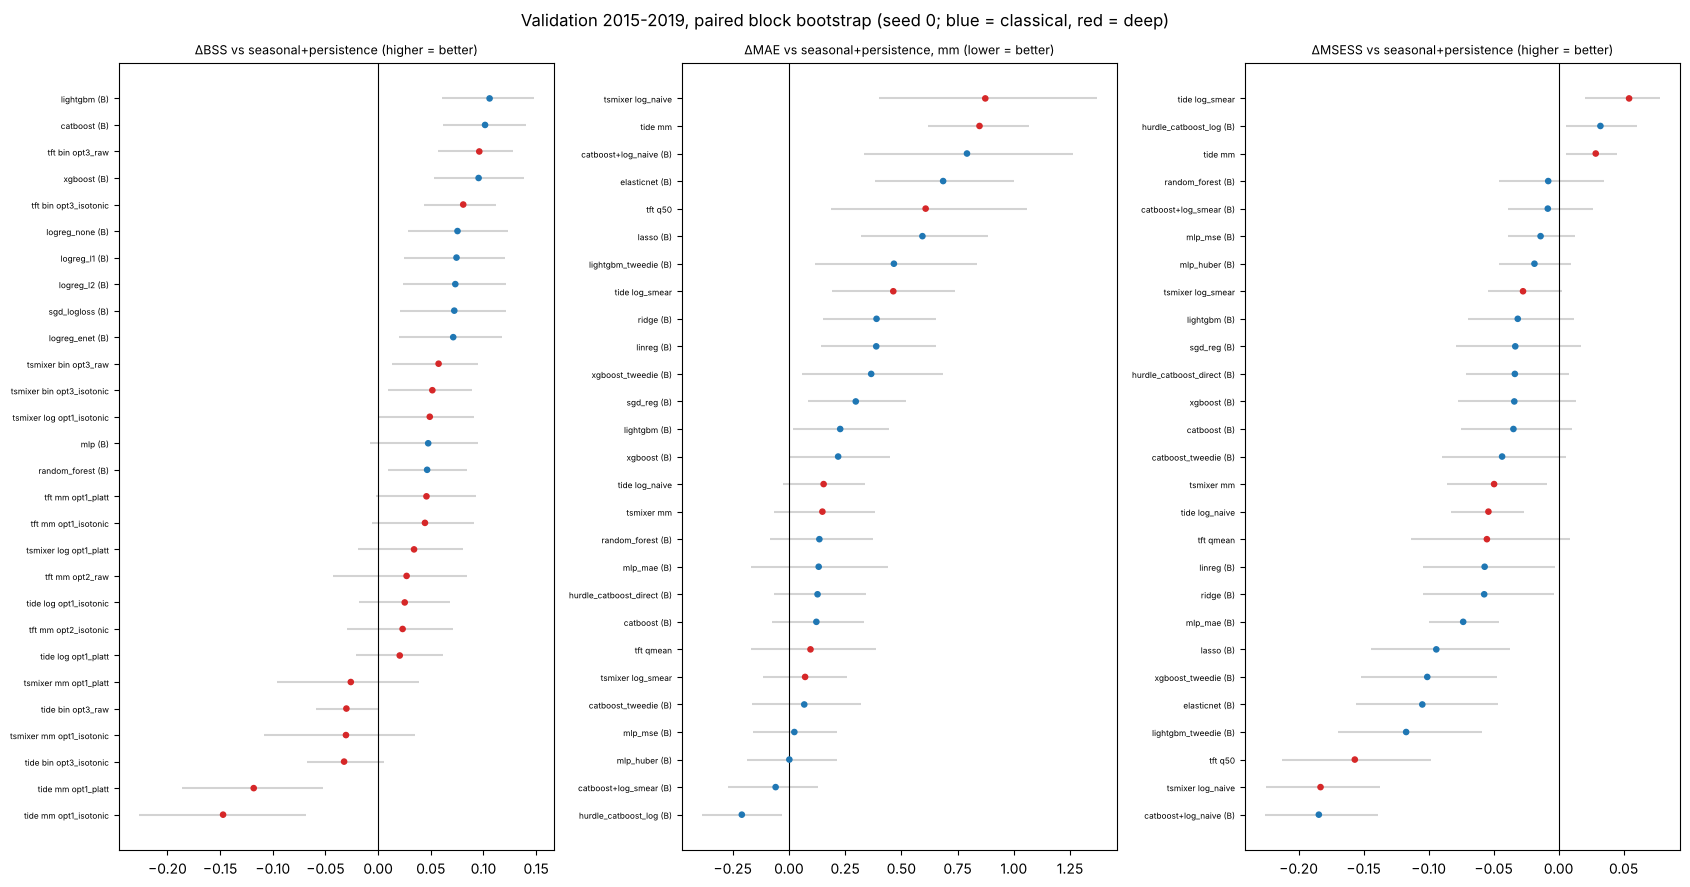

In [13]:
COL = {"baseline": "grey", "classical": "tab:blue", "deep": "tab:red"}
fam = lambda m: "baseline" if m.startswith("baseline") else ("classical" if m.endswith("(B)") else "deep")
panels = [(pc, "dBSS", "ΔBSS vs seasonal+persistence (higher = better)"),
          (pr, "dMAE", "ΔMAE vs seasonal+persistence, mm (lower = better)"),
          (pr, "dMSESS", "ΔMSESS vs seasonal+persistence (higher = better)")]
fig, axes = plt.subplots(1, 3, figsize=(17, 9))
for ax, (p, metric, title) in zip(axes, panels):
    s = p[(p.metric == metric) & (p.reference == "baseline:seasonal+persistence") & ~p.model.str.startswith("baseline")]
    s = s[~s.model.str.contains("opt1_raw")].sort_values("estimate")
    ax.errorbar(s.estimate, range(len(s)), xerr=[s.estimate - s.ci_low, s.ci_high - s.estimate], fmt="none", ecolor="lightgrey")
    ax.scatter(s.estimate, range(len(s)), c=[COL[fam(m)] for m in s.model], s=14, zorder=3)
    ax.set_yticks(range(len(s)), s.model, fontsize=6); ax.axvline(0, color="k", lw=0.8); ax.set_title(title, fontsize=9)
fig.suptitle("Validation 2015-2019, paired block bootstrap (seed 0; blue = classical, red = deep)")
fig.tight_layout(); save(fig, "05_comparison_paired.png"); plt.show()

**Interpretation:** the chart summarises Step 12. In classification, the classical boosters (blue) and TFT Bernoulli (red) form the
top group, clearly to the right of zero. In regression MAE, only the hurdle CatBoost log model's CI lies fully left of zero. Many CIs lie
fully to the right (e.g. TFT q50, TiDE mm, the linear models, the Tweedie boosters): the baseline is hard to beat on MAE. In MSESS,
the TiDE variants and the hurdle model are the only ones clearly to the right. The deep models (red) spread widely; the
classical boosters cluster tightly.

**Decision:** this figure goes into the paper (`05_comparison_paired.png`) as the main comparison graphic.

**Paper note:** *Figure X shows paired skill differences relative to seasonal persistence for all models; classical boosters and the Bernoulli TFT form the leading group for classification, whereas for rainfall amounts few models differ significantly from the baseline.*

### Step 14 — Do the deep models earn their compute? Training cost vs skill

**WHAT:** mean fit time per run (one inner fit + refit + forecasts, 4 CPU cores) and the headline skill of the best configuration of each
family.

**WHY:** the paper must say whether the extra complexity buys anything.

**Look for:** skill gained per minute of compute.

In [14]:
best_cls = U[(U.task == "cls") & (U.metric == "BSS")].groupby(["family", "model"])["value"].mean()
best_reg = U[(U.task == "reg") & (U.metric.isin(["MAE", "MSESS"]))].groupby(["family", "model", "metric"])["value"].mean().unstack()
secs = U[U.metric == "fit_seconds"].groupby(["family", "model"])["value"].mean()
cost = pd.DataFrame({"BSS (cls)": best_cls, "MAE (reg)": best_reg["MAE"], "MSESS (reg)": best_reg["MSESS"], "fit seconds": secs})
cost = cost[~cost.index.get_level_values("model").str.contains("opt1_raw")]
cost.round(3).to_csv(TAB / "05_cost_vs_skill.csv")
sel = ["catboost (B)", "lightgbm (B)", "logreg_l1 (B)", "catboost_tweedie (B)", "hurdle_catboost_log (B)", "baseline:seasonal+persistence"]
deep_rows = cost.loc["deep"].dropna(how="all", subset=["BSS (cls)", "MAE (reg)"])
display(cost[cost.index.get_level_values("model").isin(sel)].round(3)); deep_rows.round(3)

BSS (cls)  MAE (reg)  MSESS (reg)  fit seconds
family    model                                                                        
baseline  baseline:seasonal+persistence      0.224      9.019        0.343          NaN
classical catboost (B)                       0.321      9.150        0.310        4.377
          catboost_tweedie (B)                 NaN      9.158        0.288        4.042
          hurdle_catboost_log (B)              NaN      8.879        0.369          NaN
          lightgbm (B)                       0.328      9.232        0.310        1.803
          logreg_l1 (B)                      0.298        NaN          NaN        9.446

,BSS (cls),MAE (reg),MSESS (reg),fit seconds
model,,,,
tft bin opt3_isotonic,0.298,NaN,NaN,NaN
tft bin opt3_raw,0.307,NaN,NaN,NaN
tft mm opt1_isotonic,0.263,NaN,NaN,NaN
tft mm opt1_platt,0.272,NaN,NaN,NaN
tft mm opt2_isotonic,0.260,NaN,NaN,NaN
tft mm opt2_raw,0.261,NaN,NaN,NaN
tft q50,NaN,9.645,0.176,292.694
tft qmean,NaN,9.185,0.280,292.694
tide bin opt3_isotonic,0.188,NaN,NaN,NaN


**Interpretation:** cost per fit (inner fit + refit + forecasts, 4 CPU cores):
- LightGBM about 1.8 s, CatBoost about 4.4 s, logreg_l1 about 9 s.
- TiDE 38–80 s.
- TFT about 293 s, i.e. **about 65× CatBoost and 160× LightGBM** for a BSS that is not significantly better (0.307 vs 0.321/0.328).
- Only TiDE log + smearing offers something the classical models do not: the best MSE and the least biased heavy-rain forecasts. It costs about 20× CatBoost and is significantly worse on MAE.

**Decision:** on this dataset, the deep models **do not earn their compute** as general-purpose forecasters. They are retained in the paper as (i) a fair, tuned comparison, (ii) the TFT for calibrated quantiles, and (iii) TiDE for heavy-rain/MSE skill.

**Paper note:** *The deep models required one to two orders of magnitude more computation than gradient boosting without a significant gain in Brier skill or MAE, although TiDE offered the lowest squared error and bias for rainfall amounts.*

### Step 15 — Red-flag checklist

**WHAT:** (a) approved rule-11 triggers on every DL-split result (classical and deep); (b) test-set audit extended to `models/dl` and
`models/deep`; (c) seed stability of the deep models.

**Look for:** 0 trigger hits; latest target 2019-12-31 everywhere; seed std of deep models vs their gains.

In [15]:
trig = {"BSS": 0.45, "ROC_AUC_monsoon": 0.90, "MSESS": 0.60}
hits = U[U.metric.isin(trig) & (U.value > U.metric.map(trig))]
print("rule-11 hits:", len(hits), "| max:", U[U.metric.isin(trig)].groupby("metric")["value"].max().round(3).to_dict())
latest = {}
for folder in (E.SPLITS["dl"][2], D.DEEP_DIR, DC.PRED_DIR):
    files = [f for f in Path(folder).glob("*.parquet")]
    latest[str(Path(folder).relative_to(ROOT))] = (len(files), str(max(S.target_dates(pd.read_parquet(f, columns=[]).index).max()
                                                                     for f in files).date()))
print("files / latest target date:", latest)
stab = U[(U.family == "deep") & U.metric.isin(["MAE", "BSS"])].groupby(["model", "metric"])["value"].agg(["mean", "std", "count"])
stab.sort_values("std", ascending=False).round(4).head(12)

rule-11 hits: 0 | max: {'BSS': 0.33, 'MSESS': 0.399, 'ROC_AUC_monsoon': 0.861}


files / latest target date: {'models/dl': (121, '2019-12-31'), 'models/deep': (110, '2019-12-31'), 'models/deep/cls': (90, '2019-12-31')}


,,mean,std,count
model,metric,,,
tsmixer mm,MAE,9.236,0.268,5
tft q50,MAE,9.645,0.263,5
tsmixer log_naive,MAE,10.072,0.181,5
tsmixer log_smear,MAE,9.195,0.137,5
tide mm,MAE,9.912,0.090,5
tft qmean,MAE,9.185,0.082,5
tsmixer log opt1_platt,BSS,0.250,0.054,5
tide log_smear,MAE,9.434,0.047,5
tsmixer log opt1_isotonic,BSS,0.260,0.038,5


**Interpretation:**
- **(a) Rule-11 triggers: 0 hits.** The best values are BSS 0.33, MSESS 0.40 and monsoon ROC-AUC 0.86, all below the thresholds approved in Stage 4 and in line with published next-day rainfall skill.
- **(b) Test-set audit:** every prediction folder (`models/dl` 121, `models/deep` 110, `models/deep/cls` 90 files) ends at target date 2019-12-31. No 2020+ target was produced.
- **(c) Seed stability:** the largest std is TSMixer and TFT q50 MAE (≈ 0.26) and TSMixer option-1 BSS (≤ 0.054). This is noisy but well below the between-family differences that we claim.

**Decision:** no red flags. The results can be reported. The large deep-model seed spread is stated in the paper.

**Paper note:** *No result exceeded the pre-registered plausibility thresholds, and an audit confirmed that no forecast for the held-out test period (2020–2025) was generated.*

### SKEPTICAL-REVIEWER

| # | Objection a reviewer would raise | Our answer / status |
|---|---|---|
| 1 | "Deep models were handicapped: little tuning, CPU budget, small hidden sizes." | True in part. Architectures were fixed a priori (small, regularised) and not tuned on validation; TiDE-Bernoulli hit the epoch cap. Stage 6 tunes the finalists with the same budget per family. We state that conclusions hold *for this data size and budget* (~12k training days, 1 location). |
| 2 | "Classical models had hand-made lag/rolling features; deep models had raw sequences." | Deliberate: each family received its natural input form, and both use only information up to day t. TFT/TiDE saw 14 days of all variables, which is a superset of the lag features. |
| 3 | "Bootstrap CIs ignore seed variance." | Correct; they use seed 0. The seed-mean ± std table is reported alongside, and claims are restricted to differences that agree in both. |
| 4 | "Many comparisons, no multiplicity correction." | Acknowledged. Our headline claims rest on large, consistent effects (boosters vs baseline, TFT vs CatBoost tie), not on borderline p-values. |
| 5 | "Validation period 2015–2019 was used for model and option comparisons, so it is not a clean holdout." | Yes. All *selections* (thresholds, calibration, early stopping, smearing) used the 2012–2014 slice. Validation is only used to rank, and the final claims will be checked once on the untouched 2020–2025 test set. |
| 6 | "Option 2 is unfair: the clamp limits it." | It is a real limitation of reading probabilities from 7 quantiles. We report it as such; option 3 is the fair deep probabilistic model. |
| 7 | "VSN/attention are presented as physical insight." | No. Step 6 states explicitly that they describe the network and are unstable across seeds. |
| 8 | "NASA POWER is a reanalysis/satellite product, not gauges." | Limitation carried from Stage 0; IMERG cross-check and gauge comparison are listed as future work. |

### Stage 5 part 2 — summary

1. **TFT (5.4):** a well-calibrated probabilistic forecaster (80 % coverage 82 %, pinball 2.96). Its median is a poor point forecast (bias −7.7 mm); the quantile mean is better (MAE 9.19) but does not beat seasonal + persistence. Lookback is insensitive (14 ≈ 30 ≈ 60). VSN favours humidity and season, and attention favours days t and t−1. Both are descriptive only.
2. **Deep classification (5.5):** Bernoulli likelihood (native in darts 0.48) is the best route. TFT reached BSS 0.307, ROC-AUC 0.965 and ECE 0.035. Calibrated mm forecasts are second (≤ 0.27). TFT-quantile probabilities are limited by the clamp (0.26). TiDE-Bernoulli is under-trained (epoch cap).
3. **Apples-to-apples (5.6):** on the identical split, the boosters remain best for classification. TFT-Bernoulli is statistically tied with CatBoost at about 65× the compute. For amounts, the hurdle CatBoost log model is the only one that significantly beats seasonal + persistence on MAE, and TiDE log + smearing is the only one with clearly better MSE and bias.
4. **Verdict:** the deep models do not earn their compute on this single-site daily dataset. They add value only for calibrated quantiles (TFT) and squared-error/heavy-rain skill (TiDE).
5. **Integrity:** 0 rule-11 hits, no test-period forecasts, seed variability reported, TiDE config correction disclosed (DECISIONS 5.7).

Outputs: `src/deep_cls.py`, `src/compare.py`, updated `src/deep_ts.py` / `src/experiment.py` / `src/reg_variants.py`;
`models/deep/` (incl. `tft_*`), `models/deep/cls/`, `models/dl/`; tables `05_deep_regression_L14.csv`, `05_lookback_sensitivity.csv`,
`05_tft_encoder_importance.csv`, `05_deep_classification_L14.csv`, `05_master_classification_dl.csv`, `05_master_regression_dl.csv`,
`05_paired_bootstrap_cls.csv`, `05_paired_bootstrap_reg.csv`, `05_cost_vs_skill.csv`; figures `05_tft_quantiles.png`,
`05_tft_explainability.png`, `05_deep_reliability.png`, `05_comparison_paired.png`.